In [1]:
import os

print("Current folder:", os.getcwd())

print("\nAvailable files:")
print(os.listdir())

Current folder: c:\Users\nidhi\OneDrive\Desktop\project\notebooks

Available files:
['best_decision_tree_churn.pkl', 'categorical_analysis.ipynb', 'Day7_Decision_Tree_Comparison.ipynb', 'Day8_Save_Best_Decision_Tree.ipynb', 'Day9_Decision_Tree_Testing.ipynb', 'decision_tree.ipynb', 'decision_tree_tuning.ipynb', 'eda_analysis.py', 'feature_encoding.ipynb']


In [2]:
import os

# Check the parent project folder
project_path = os.path.dirname(os.getcwd())

print("Project folder:", project_path)
print("\nFiles in project folder:")
print(os.listdir(project_path))

Project folder: c:\Users\nidhi\OneDrive\Desktop\project

Files in project folder:
['.venv', 'app', 'categorical_analysis.ipynb', 'cleaned_churn_data.csv', 'data', 'eda_analysis.py', 'graphs', 'models', 'notebooks', 'outpur graph2.pns.png', 'output.png', 'README.md', 'src']


In [1]:
import pandas as pd

# Load the cleaned dataset
df = pd.read_csv("../cleaned_churn_data.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

# Display first 5 rows
df.head()

Dataset loaded successfully!
Dataset shape: (7043, 26)


,City,Zip Code,Lat Long,Latitude,Longitude,Gender,Senior Citizen,Partner,Dependents,Tenure Months,...,Tech Support,Streaming TV,Streaming Movies,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Label,CLTV
0,Los Angeles,90003,"33.964131, -118.272783",33.964131,-118.272783,Male,No,No,No,2,...,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,3239
1,Los Angeles,90005,"34.059281, -118.30742",34.059281,-118.307420,Female,No,No,Yes,2,...,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,2701
2,Los Angeles,90006,"34.048013, -118.293953",34.048013,-118.293953,Female,No,No,Yes,8,...,No,Yes,Yes,Month-to-month,Yes,Electronic check,99.65,820.5,Yes,5372
3,Los Angeles,90010,"34.062125, -118.315709",34.062125,-118.315709,Female,No,Yes,Yes,28,...,Yes,Yes,Yes,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes,5003
4,Los Angeles,90015,"34.039224, -118.266293",34.039224,-118.266293,Male,No,No,Yes,49,...,No,Yes,Yes,Month-to-month,Yes,Bank transfer (automatic),103.70,5036.3,Yes,5340


In [2]:
# Display all column names
print(df.columns.tolist())

# Check churn distribution
print("\nChurn Label Distribution:")
print(df['Churn Label'].value_counts())

['City', 'Zip Code', 'Lat Long', 'Latitude', 'Longitude', 'Gender', 'Senior Citizen', 'Partner', 'Dependents', 'Tenure Months', 'Phone Service', 'Multiple Lines', 'Internet Service', 'Online Security', 'Online Backup', 'Device Protection', 'Tech Support', 'Streaming TV', 'Streaming Movies', 'Contract', 'Paperless Billing', 'Payment Method', 'Monthly Charges', 'Total Charges', 'Churn Label', 'CLTV']

Churn Label Distribution:
Churn Label
No     5174
Yes    1869
Name: count, dtype: int64


In [3]:
# Load the encoded dataset
encoded_df = pd.read_csv("../data/encoded_churn_data.csv")

print("Encoded dataset loaded successfully!")
print("Dataset shape:", encoded_df.shape)

print("\nColumn names:")
print(encoded_df.columns.tolist())

print("\nFirst 5 rows:")
display(encoded_df.head())

Encoded dataset loaded successfully!
Dataset shape: (7043, 34)

Column names:
['Latitude', 'Longitude', 'Tenure Months', 'Monthly Charges', 'Total Charges', 'Churn Label', 'CLTV', 'Gender_Male', 'Senior Citizen_Yes', 'Partner_Yes', 'Dependents_Yes', 'Phone Service_Yes', 'Multiple Lines_No phone service', 'Multiple Lines_Yes', 'Internet Service_Fiber optic', 'Internet Service_No', 'Online Security_No internet service', 'Online Security_Yes', 'Online Backup_No internet service', 'Online Backup_Yes', 'Device Protection_No internet service', 'Device Protection_Yes', 'Tech Support_No internet service', 'Tech Support_Yes', 'Streaming TV_No internet service', 'Streaming TV_Yes', 'Streaming Movies_No internet service', 'Streaming Movies_Yes', 'Contract_One year', 'Contract_Two year', 'Paperless Billing_Yes', 'Payment Method_Credit card (automatic)', 'Payment Method_Electronic check', 'Payment Method_Mailed check']

First 5 rows:


,Latitude,Longitude,Tenure Months,Monthly Charges,Total Charges,Churn Label,CLTV,Gender_Male,Senior Citizen_Yes,Partner_Yes,...,Streaming TV_No internet service,Streaming TV_Yes,Streaming Movies_No internet service,Streaming Movies_Yes,Contract_One year,Contract_Two year,Paperless Billing_Yes,Payment Method_Credit card (automatic),Payment Method_Electronic check,Payment Method_Mailed check
0,33.964131,-118.272783,2,53.85,108.15,1,3239,1,0,0,...,0,0,0,0,0,0,1,0,0,1
1,34.059281,-118.307420,2,70.70,151.65,1,2701,0,0,0,...,0,0,0,0,0,0,1,0,1,0
2,34.048013,-118.293953,8,99.65,820.50,1,5372,0,0,0,...,0,1,0,1,0,0,1,0,1,0
3,34.062125,-118.315709,28,104.80,3046.05,1,5003,0,0,1,...,0,1,0,1,0,0,1,0,1,0
4,34.039224,-118.266293,49,103.70,5036.30,1,5340,1,0,0,...,0,1,0,1,0,0,1,0,0,0


In [4]:
print("Target data type:")
print(encoded_df['Churn Label'].dtype)

print("\nTarget values:")
print(encoded_df['Churn Label'].value_counts())

print("\nMissing values:")
print(encoded_df['Churn Label'].isnull().sum())

Target data type:
int64

Target values:
Churn Label
0    5174
1    1869
Name: count, dtype: int64

Missing values:
0


In [5]:
from sklearn.model_selection import train_test_split

# Separate features and target
X = encoded_df.drop('Churn Label', axis=1)
y = encoded_df['Churn Label']

# Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training targets:", y_train.shape)
print("Testing targets:", y_test.shape)

Training features: (5634, 33)
Testing features: (1409, 33)
Training targets: (5634,)
Testing targets: (1409,)


In [6]:
import joblib

# Load the saved best Decision Tree model
best_dt_model = joblib.load("../models/best_decision_tree_model.pkl")

print("Best Decision Tree model loaded successfully!")

Best Decision Tree model loaded successfully!


In [7]:
# Generate predictions using the saved model
y_pred = best_dt_model.predict(X_test)

print("Predictions generated successfully!")

print("\nFirst 10 Actual Values:")
print(y_test.head(10).tolist())

print("\nFirst 10 Predicted Values:")
print(y_pred[:10])

Predictions generated successfully!

First 10 Actual Values:
[0, 0, 0, 0, 0, 0, 0, 0, 0, 1]

First 10 Predicted Values:
[0 1 0 0 0 0 0 0 0 0]


In [8]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Calculate evaluation metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print("Decision Tree Model Evaluation")
print("--------------------------------")
print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("F1 Score:", f1)

Decision Tree Model Evaluation
--------------------------------
Accuracy: 0.7863733144073811
Precision: 0.6130030959752322
Recall: 0.5294117647058824
F1 Score: 0.5681492109038737


Confusion Matrix:
[[910 125]
 [176 198]]


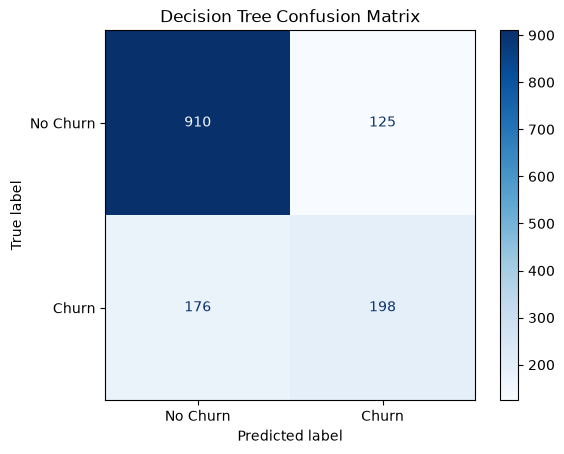

In [9]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Generate confusion matrix
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

# Display confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Churn", "Churn"]
)

disp.plot(cmap="Blues")
plt.title("Decision Tree Confusion Matrix")
plt.show()